# Base-model variety vs nudgeable coding tasks (panel B) — demo

**Artifact:** `art_9a8LrIv2lHbV` (iteration 5, panel B of two) · **Models:** Qwen3-8B (instruct, rev `b968826d`) and Qwen3-8B-Base (rev `49e3418f`), bf16, thinking off, T = 1.0

**The question behind it.** Ask an instruct LLM for a function that "returns the one number that appears once", and it writes nearly the same algorithm every time (here a hash-map count). Is that default just the *average answer* of a probabilistic model? And can a nudge to the model's internals move it to a different, still-correct algorithm? This experiment tests one **ban-free** predictor of *which* coding tasks can be nudged at all:

* **Units.** Each coding unit is a task, its hidden tests (two oracles) and a catalogue of 3–6 correct algorithms with gated runtime + AST labellers. The task wording names no algorithm.
* **Default.** The **instruct twin** (N = 50) fixes the default algorithm.
* **Base repertoire.** The **base model** is sampled N = 200 times on the *identical chat-templated token ids*. Its correct-only repertoire gives:
  * **β_u**: the share of correct base programs whose algorithm is *not* the instruct default, i.e. how much variety the pre-trained model has;
  * **r_u**: the base model's most frequent correct non-default algorithm (its runner-up).
* **Commitment.** β_u, r_u and every rival predictor are **sha256-hash-committed before any push sample**.
* **Pushes.** The instruct model then gets **8 isotropic random directions × α ∈ {1, 2}**, added to the residual stream at the task-spec token positions of blocks 12–23 (prefill only, step α · r_Q · ‖h‖).
* **Escape.** A (direction, α) cell **escapes** when the off-default share rises ≥ 0.20 above the twin and an exact binomial test confirms it at N = 30. **E_u** is the escaping share of the 16 cells.
* **Claim A1:** β_u ranks E_u across units (a diverse base model means a movable instruct model).
* **Claim A2:** when pushes do move the model, they land on r_u more often than chance, and better than an association forecast (ASSOC) or an AST-proximity forecast (PROX).

The full run sampled **14,600 programs (1.74 GPU-hours on one RTX 4090)** and spent about USD 0.19 on LLM-judge calls. That part needs a GPU and both 8B models, so **it is not re-run here**.

**What this notebook runs**
1. **`method.py`**, the artifact's entry point (the demo file), cell by cell and almost verbatim. It is a stage orchestrator; its commands are *logged* (dry run) because the `src/` stage scripts, the GPU and the weights are not part of a notebook.
2. **The CPU-only core of its default `final` stage**, copied from the artifact with minimal changes:
   * `analysis/a1a2.py`: A1 with rivals, sensitivities and placebo; A2;
   * the escape rule of `src/labels_view.py`;
   * `analysis/a1_extended.py`: the panel + parents and cluster-preserving views;
   * `analysis/variants.py`: the within-parent test with disguised variants.

   They run on `mini_demo_data.json`, the artifact's **23 per-unit records**: 7 new units B1–B7, 8 parent re-measures `P_*` and 8 disguised variants `V_*`. Each record holds the committed predictions and the measured push outcomes.

Section 9 compares every re-computed headline number with the artifact's committed `results/*.json`.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install (method.py logs through it)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# ---- method.py (original import block) ----
import argparse
import subprocess
import sys
from pathlib import Path

from loguru import logger

# ---- analysis/a1a2.py, analysis/a1_extended.py, analysis/variants.py (original imports; `csv` is dropped because
#      the notebook keeps results in memory instead of writing results/*.json and results/units_table.csv) ----
import itertools
import json
import math
from collections import Counter
from typing import Any

import numpy as np
from scipy import stats

# ---- notebook additions: tables and figures ----
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-5/experiment-26/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()

# one record per unit (dataset `panelB_units` of the artifact's method_out.json)
EXAMPLES = {ex["metadata_unit"]: ex for ex in data["datasets"][0]["examples"]}
print(data["metadata"]["source_artifact"])
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(EXAMPLES)} unit records:", ", ".join(EXAMPLES))
ex = EXAMPLES["B2"]
print("\nExample record B2. The task both models get (inside the chat template):\n  " + ex["input"][:420] + " ...")
print(f"  instruct default = {ex['output']} | beta_u = {ex['metadata_beta_u']:.3f} | r_u = {ex['metadata_r_u']} | "
      f"E_u = {ex['metadata_E_u']} | push landing = {ex['metadata_push_landing']}")
print("  base model, correct programs by algorithm:", ex["metadata_base_correct_composition"])
print("  instruct twin, correct programs by algorithm:", ex["metadata_twin_correct_composition"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
art_9a8LrIv2lHbV -- Base-model variety vs nudgeable coding tasks (panel B), iteration 5
dataset 'panelB_units': 23 unit records: B1, B2, B3, B4, B5, B6, B7, P_R1, P_T03, P_T04, P_T05, P_T06, P_T08, P_T10, P_T14, V_R1, V_T03, V_T04, V_T05, V_T06, V_T08, V_T10, V_T14

Example record B2. The task both models get (inside the chat template):
  Task: write a Python function solve(nums) that returns the value that occurs exactly once in nums. The argument nums is a list of integers with 1 <= len(nums) <= 100001, and every value lies between -30000 and 30000 inclusive. Every value in nums occurs exactly twice except one value, which occurs exactly once; return that value as an int. For example, for nums = [4, 1, 2, 1, 2] the answer is 4, and for nums = [7] th ...
  instruct default = hash_count | beta_u = 0.565 | r_u = xor_fold | E_u = 0.4375 | push landing = xor_fold
  base model, correct programs by algorithm

## Configuration

Every tunable parameter is in the next cell:

* `method.py` takes one argument, `--stage` (default `final`). `DRY_RUN` controls whether its stage commands are executed or only logged.
* The frozen analysis has six Monte-Carlo sizes: shuffles, bootstrap resamples, placebo repetitions and rarefaction subsamples.

**The cell uses the artifact's original values.** At those values the analysis takes about 25 s of compute, and all 42 headline quantities in section 9 reproduce the artifact's committed results exactly. The whole notebook, installs included, ran in about one minute in a clean Colab-like environment.

**Smaller values run faster** (e.g. 100 / 100 / 100 / 10 / 100 / 10, about 2 s of compute) **but change** the bootstrap CIs, the placebo and the shuffle p-values (n > 9). The Spearman ρ values, exact-enumeration p-values (n ≤ 9), A2 and the variants analysis do not depend on them.

In [5]:
# ---- method.py ----
STAGE = "final"     # --stage: 'final' (the default of `uv run method.py`), a comma-separated list of stages, or 'all'
DRY_RUN = True      # log each stage command instead of running it (the src/ scripts, a GPU and the models are not here)

# ---- Monte-Carlo sizes of the frozen analysis: the artifact's original values (about 25 s of compute) ----
N_SHUFFLE = 10000          # a1a2.perm_p: random shuffles when n > 9 (n <= 9 is enumerated exactly)   (original: 10000)
N_BOOT = 10000             # a1a2.boot_ci: unit-bootstrap resamples for the 95% CI of rho          (original: 10000)
N_RIVAL_BOOT = 10000       # a1a2.a1: paired bootstrap of rho(beta, E) - rho(rival, E)              (original: 10000)
N_PLACEBO = 1000           # a1a2.a1: shuffled-beta placebo repetitions                             (original: 1000)
N_CLUSTER_SHUFFLE = 10000  # a1_extended.clustered_p: cluster-preserving shuffles                   (original: 10000)
N_RAREFY_SUB = 1000        # a1a2.rarefied: subsamples per rarefied Hill-1 (only its RNG draws are replayed here) (original: 1000)

## 1. `method.py`: the orchestrator

`method.py` holds no science of its own. It runs the artifact's pipeline as a fixed sequence of **stages**, and each stage is a script under `src/`, `analysis/` or `audit/`:

| stage | what it does | needs |
|---|---|---|
| `setup` | extract dependency rows, render prompts, commit #0 (protocol and analysis rules frozen) | CPU |
| `build` | build units B1–B7: hidden tests (two oracles), references, mutants, excluded brute force, gate stage (i) | CPU |
| `gpu-i1` | instruct model: GPU tests, engine check, twins (→ default), novelty + association arms | GPU, Qwen3-8B |
| `gpu-b1` | base model: chat repertoire (N = 200) + plain completion (N = 50) | GPU, Qwen3-8B-Base |
| `label` | label worker: hidden tests, runtime tracer, AST labeller, blind judges on disagreement | CPU, OpenRouter |
| `gate` | gate stage (ii): gold set, two blind judges, kappa (+ one revision round) | CPU, OpenRouter |
| `commit` | per-unit predictions (β_u, r_u, rivals, forecasts) + sha256 hash chain, **before any push** | CPU |
| `push` | escape population (8 directions × α 1, 2), confirmations, plan noise, T = 1.3 | GPU |
| `extra` | disguised variants + paired parent re-measures | GPU |
| `final` | adjudication, analysis, audits, figures, outputs (**the default**) | CPU |

The next cell is the module header of `method.py`, verbatim apart from two notebook fixes:
* the module docstring is assigned to `__doc__` (`main()` reads it, and a bare string at the top of a cell does not set it);
* `ROOT` is the current directory, because a notebook has no `__file__`.

In [6]:
# notebook: method.py's module docstring, assigned explicitly (main() uses __doc__ for the argparse description)
__doc__ = """Panel B of the iteration-5 confirmation (Claims A1/A2) on Qwen3-8B (instruct) and Qwen3-8B-Base.

METHOD (ours): a ban-free, base-derived predictor of push movability. For every coding unit, the base model's
repertoire under the identical chat-templated prompt gives beta_u (share of correct base programs whose mechanism is
not the instruct twin's default) and r_u (the base model's most frequent correct non-default mechanism). Both are
hash-committed BEFORE the unit's first push sample. A1: does beta_u rank the escape fraction E_u of isotropic random
pushes (8 directions x alpha 1, 2; task-spec positions, blocks 12-23, prefill only) across units? A2: does r_u (and
the base composition) forecast where the pushes land?
BASELINES / RIVALS (same frozen material, committed beside beta): R_modal (1 - twin modal share), R_margin (opening
log-prob margin of the default over the best survivor), R_merit (runtime and length of the fastest non-default
reference vs the default's), R_novel (novelty-instruction off-default share), K_u (catalogue size) for A1; ASSOC
(association answers) and PROX (AST proximity) forecasts against BASE for A2; plus shuffled-beta, shuffled-arm and
twin-as-push placebos.

This file orchestrates the stages implemented in src/ (see README.md for the full layout):
  setup     extract dependency rows, render prompts, commit #0           (src/extract_sources.py, src/protocol0.py)
  build     unit build + gate stage (i) for B1-B7                         (src/unitbuild.py)
  gpu-i1    instruct: GPU tests, engine check, twins/novelty/association  (src/gpu_main.py)
  gpu-b1    base: chat repertoire (N = 200) + plain completion            (src/gpu_main.py)
  label     CPU label worker (runtime primary, AST second, judges on disagreement)   (src/label5.py)
  gate      gate stage (ii) (+ one revision round)                        (src/gate2.py)
  commit    per-unit predictions + hash chain                             (src/quantities.py, src/quantities_extra.py)
  push      escape population, confirmations, PN, T1.3                     (src/gpu_main.py --phases push)
  extra     disguised variants + paired parents                           (src/units_extra.py, gpu phases extra_*)
  final     analysis, audits, figures and outputs (CPU only; this is what `uv run method.py` runs by default)
"""

ROOT = Path.cwd()  # notebook: method.py uses Path(__file__).resolve().parent
PY = sys.executable
UNITS = "B1,B2,B3,B4,B5,B6,B7"
PAIRS = "T03,T10,T05,T06,T04,T08,T14,R1"

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
(ROOT / "logs").mkdir(exist_ok=True)
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG");  # notebook: `;` hides the handler id

### Stage table and runner

`run()` executes one stage script in a subprocess and stops the pipeline on the first failure. `STAGES` maps each stage name to its ordered list of script commands. Both are copied verbatim. The single addition is the `DRY_RUN` guard in `run()`: when it is set, the command is logged and not executed.

A few details from the table:
* `gpu-b1` runs with `--n-base 40`: 40 slots × 5 templates, i.e. N = 200 base programs per unit.
* The `extra` stage builds the `P_<task>` / `V_<task>` unit lists for the 8 parent tasks.
* `final` chains 15 scripts: adjudication, engine check, the three analyses shown below, the screen view, novelty audit, re-derivation, commit-order proof, tests, vendor check, figures and outputs.

In [7]:
def run(args: list[str], cwd: Path | None = None) -> None:
    logger.info(f"$ {' '.join(args)}")
    if DRY_RUN:  # notebook: the stage scripts are not shipped with the demo -- log the command only
        return
    r = subprocess.run([PY] + args, cwd=str(cwd or ROOT))
    if r.returncode != 0:
        raise RuntimeError(f"stage failed ({r.returncode}): {' '.join(args)}")


STAGES = {
    "setup": [["src/extract_sources.py"], ["src/protocol0.py"]],
    "build": [["src/unitbuild.py", UNITS]],
    "gpu-i1": [["src/gpu_main.py", "--model", "instruct", "--phases", "tests,engine,inst1,margins", "--units", UNITS]],
    "gpu-b1": [["src/gpu_main.py", "--model", "base", "--phases", "base1", "--units", UNITS, "--n-base", "40"]],
    "label": [["src/label5.py", "--once"]],
    "gate": [["src/gate2.py", UNITS]],
    "commit": [["src/quantities.py", UNITS]],
    "push": [["src/gpu_main.py", "--model", "instruct", "--phases", "push", "--units", UNITS]],
    "extra": [["src/units_extra.py"],
              ["src/gpu_main.py", "--model", "instruct", "--phases", "extra_inst", "--pairs", PAIRS],
              ["src/gpu_main.py", "--model", "base", "--phases", "extra_base", "--pairs", PAIRS],
              ["src/quantities_extra.py", ",".join(f"{p}{t}" for t in PAIRS.split(",") for p in ("P_", "V_"))],
              ["src/gpu_main.py", "--model", "instruct", "--phases", "push", "--arms", "esc,conf", "--units",
               ",".join(f"{p}{t}" for t in PAIRS.split(",") for p in ("P_", "V_"))]],
    "final": [["src/adjudicate_all.py"], ["src/engine_check.py"], ["analysis/a1a2.py"], ["analysis/variants.py"], ["analysis/a1_extended.py"],
              ["analysis/screen_view.py"], ["src/novelty_audit.py"], ["audit/rederive.py"], ["audit/commit_order.py"], ["tests/test_analysis.py"],
              ["tests/test_cpu.py"], ["tests/test_datasets.py"], ["src/vendor_check.py"], ["src/figures.py"], ["src/outputs.py"]],
}

### `main()`: running the selected stages

This is verbatim except for one line. A notebook has no command line, so `parse_args` receives `["--stage", STAGE]` from the config cell. With `STAGE = "final"` and `DRY_RUN = True` the cell lists the 15 scripts of the final stage in order. Set `STAGE = "all"` to see every command of the whole pipeline.

Sections 2–8 then run the core of three of those scripts on the loaded records: `analysis/a1a2.py`, `analysis/variants.py` and `analysis/a1_extended.py`.

In [8]:
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser(description=__doc__.split("\n")[0])
    ap.add_argument("--stage", default="final", help="comma-separated stages, or 'all'; see the module docstring")
    a = ap.parse_args(["--stage", STAGE])  # notebook: was ap.parse_args() (command line)
    order = list(STAGES) if a.stage == "all" else a.stage.split(",")
    for s in order:
        if s not in STAGES:
            raise ValueError(f"unknown stage {s}; choose from {list(STAGES)}")
        logger.info(f"=== stage {s}")
        for cmd in STAGES[s]:
            run(cmd)
    logger.info("done")


if __name__ == "__main__":
    main()

08:42:33|INFO   |=== stage final


08:42:33|INFO   |$ src/adjudicate_all.py


08:42:33|INFO   |$ src/engine_check.py


08:42:33|INFO   |$ analysis/a1a2.py


08:42:33|INFO   |$ analysis/variants.py


...

08:42:33|INFO   |$ tests/test_datasets.py


08:42:33|INFO   |$ src/vendor_check.py


08:42:33|INFO   |$ src/figures.py


08:42:33|INFO   |$ src/outputs.py


08:42:33|INFO   |done


## 2. Inside the `final` stage: the frozen A1/A2 analysis (`analysis/a1a2.py`)

`analysis/a1a2.py` was **hash-committed before the first push sample** of any unit, so the analysis could not be tuned on the outcomes. Its statistical helpers are copied verbatim below. Two things change: the Monte-Carlo sizes default to the config values, and the few constants it imports from `src/cfg5.py` and `src/labels_view.py` are written inline.

* `spearman`: Spearman ρ with average ranks.
* `perm_p`: exact one-sided permutation p. It enumerates all n! orderings when n ≤ 9 (7! = 5040 for the 7 new units) and shuffles randomly otherwise.
* `boot_ci`: unit-bootstrap 95% CI of ρ.
* `partial_spearman`: ρ after regressing out the ranks of a covariate (catalogue size K_u).
* `clopper_pearson`: exact binomial CI.
* `poisson_binomial_sf`: exact P(X ≥ hits) for a sum of independent Bernoullis with *different* chance rates. In A2 each unit's chance is 1/(K_u − 1).
* `js_divergence`, `hill1`, `rarefied`: Jensen–Shannon divergence and the (rarefied, depth 25) Hill-1 diversity of an algorithm composition.

All Monte-Carlo draws share one generator, `RNG = np.random.default_rng(5)`, exactly as in the original module.

In [9]:
RNG = np.random.default_rng(5)
UNIT_IDS = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B9"]

# notebook: constants the original imports from src/cfg5.py and src/labels_view.py
ALPHAS = (1.0, 2.0)                  # push sizes alpha (in units of r_Q * ||h||)
N_DIRS = 8                           # isotropic directions per alpha
ESC_EXCESS = 0.20                    # escape: off-default share >= twin share + 0.20 ...
ESC_PASS_FRAC = 0.8                  # ... and pass rate >= 0.8 x twin pass rate
EXCLUDE = ("invalid", "disputed")    # labels excluded from the share denominator


def rankdata(x: list[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: list[float], y: list[float]) -> float | None:
    if len(x) < 3:
        return None
    rx, ry = rankdata(x), rankdata(y)
    if np.std(rx) == 0 or np.std(ry) == 0:
        return None
    return float(np.corrcoef(rx, ry)[0, 1])


def perm_p(x: list[float], y: list[float], n_shuffle: int = N_SHUFFLE) -> dict[str, Any]:
    """Exact one-sided (greater) permutation p for Spearman rho: full enumeration if n <= 9."""
    r0 = spearman(x, y)
    if r0 is None:
        return {"rho": None, "p": None, "method": "undefined (constant ranks or n < 3)"}
    n = len(x)
    rx, ry = rankdata(x), rankdata(y)
    if n <= 9:
        perms = np.array(list(itertools.permutations(range(n))))
        ys = ry[perms]
        rxc = rx - rx.mean()
        ysc = ys - ys.mean(axis=1, keepdims=True)
        rr = (ysc @ rxc) / (np.sqrt((ysc ** 2).sum(axis=1)) * np.sqrt((rxc ** 2).sum()))
        p = float((rr >= r0 - 1e-12).mean())
        return {"rho": r0, "p": p, "method": f"exact enumeration ({len(perms)} permutations)", "n": n}
    cnt = 0
    for _ in range(n_shuffle):
        r = spearman(x, list(RNG.permutation(y)))
        cnt += (r is not None and r >= r0 - 1e-12)
    return {"rho": r0, "p": (cnt + 1) / (n_shuffle + 1), "method": f"{n_shuffle} shuffles", "n": n}


def boot_ci(x: list[float], y: list[float], n_boot: int = N_BOOT) -> list[float] | None:
    n = len(x)
    if n < 3:
        return None
    xs, ys = np.asarray(x), np.asarray(y)
    vals = []
    for _ in range(n_boot):
        idx = RNG.integers(0, n, n)
        r = spearman(list(xs[idx]), list(ys[idx]))
        if r is not None:
            vals.append(r)
    if len(vals) < 100:
        return None
    return [float(np.quantile(vals, 0.025)), float(np.quantile(vals, 0.975))]


def partial_spearman(x: list[float], y: list[float], z: list[float]) -> float | None:
    if len(x) < 4:
        return None
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    if np.std(rz) == 0:
        return spearman(x, y)

    def resid(a):
        A = np.vstack([rz, np.ones_like(rz)]).T
        coef, *_ = np.linalg.lstsq(A, a, rcond=None)
        return a - A @ coef
    ex, ey = resid(rx), resid(ry)
    if np.std(ex) == 0 or np.std(ey) == 0:
        return None
    return float(np.corrcoef(ex, ey)[0, 1])


def clopper_pearson(k: int, n: int, a: float = 0.05) -> list[float] | None:
    if n == 0:
        return None
    lo = 0.0 if k == 0 else float(stats.beta.ppf(a / 2, k, n - k + 1))
    hi = 1.0 if k == n else float(stats.beta.ppf(1 - a / 2, k + 1, n - k))
    return [lo, hi]


def poisson_binomial_sf(hits: float, probs: list[float]) -> float | None:
    """P(X >= hits) for X = sum of independent Bernoulli(p_i) (hits may be fractional under ties: ceil)."""
    if not probs:
        return None
    dist = np.zeros(len(probs) + 1)
    dist[0] = 1.0
    for p in probs:
        dist[1:] = dist[1:] * (1 - p) + dist[:-1] * p
        dist[0] *= (1 - p)
    k = int(math.ceil(hits - 1e-9))
    return float(dist[k:].sum())


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float | None:
    keys = sorted(set(p) | set(q))
    P = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    Q = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    if P.sum() == 0 or Q.sum() == 0:
        return None
    P, Q = P / P.sum(), Q / Q.sum()
    M = (P + Q) / 2

    def kl(a, b):
        m = a > 0
        return float((a[m] * np.log(a[m] / b[m])).sum())
    return 0.5 * kl(P, M) + 0.5 * kl(Q, M)


def hill1(labels: list[str]) -> float | None:
    c = Counter(labels)
    n = sum(c.values())
    if n == 0:
        return None
    return math.exp(-sum(v / n * math.log(v / n) for v in c.values()))


def rarefied(labels: list[str], depth: int = 25, n_sub: int = N_RAREFY_SUB) -> float | None:
    if len(labels) < depth:
        return hill1(labels)
    arr = np.array(labels)
    return float(np.mean([hill1(list(RNG.choice(arr, size=depth, replace=False))) for _ in range(n_sub)]))

## 3. Push outcomes: the escape rule (`src/labels_view.py`)

Each push cell is one (direction, α) pair. Its programs are labelled by algorithm (runtime tracer + AST labeller, blind judges on disagreement), and labels outside the unit's frozen catalogue become `other`. Then:

* **share** = catalogue off-default labels / valid attempts. **pass** = programs passing the hidden tests / attempts.
* **stage 1** (N = 10: 2 slots × 5 neutral templates) passes when share ≥ twin share + 0.20 **and** pass ≥ 0.8 × twin pass.
* **confirmed** when the pooled N = 30 keeps an excess ≥ 0.20, a one-sided exact binomial test against p0 = (k_twin + 0.5)/(n_twin + 1) gives p < 0.05, and the pass rate holds.
* **E_α** = confirmed directions / 8. **E_u** = mean of E_1 and E_2. **Push landing** = the most frequent correct off-default algorithm, pooled over the confirmed cells.

The per-program rows (`data/labels.jsonl`, 14,600 programs) are not shipped with the demo. Instead, the cell below re-applies the rule to each unit's **stored cell summaries**:
* the twin cell (share, pass);
* per direction: the stage-1 share and pass, the pooled excess and the binomial p.

It then recomputes E_u. The pooled pass rate is not stored per cell, so that one condition is not re-checked.

In [10]:
def recheck_escape_rule(u: str) -> dict[str, Any]:
    """Re-apply the frozen escape rule (labels_view.direction_table) to one unit's stored per-direction cell
    summaries, then recompute E_alpha and E_u (notebook addition: the rows behind the cells are not shipped)."""
    ex = EXAMPLES[u]
    tw = ex["metadata_twin_cell"]
    cells = ex["metadata_per_direction"]
    n_ok = 0
    for c in cells:
        st1 = (c["stage1_share"] is not None and tw["share"] is not None and
               c["stage1_share"] - tw["share"] >= ESC_EXCESS - 1e-12 and
               c["stage1_pass"] >= ESC_PASS_FRAC * tw["pass"] - 1e-12)
        conf = bool(st1 and c["p"] is not None and c["p"] < 0.05 and c["excess_pooled"] >= ESC_EXCESS - 1e-12)
        n_ok += (st1 == c["stage1_passed"]) and (conf == c["confirmed"])
    E = {}
    for a in ALPHAS:  # as in direction_table: confirmed directions / number of seeds, per alpha
        E[str(a)] = sum(c["confirmed"] for c in cells if c["alpha"] == a) / N_DIRS
    return {"unit": u, "default": ex["output"], "twin_share": tw["share"], "twin_pass": tw["pass"],
            "stage1_passed": sum(c["stage1_passed"] for c in cells), "confirmed": sum(c["confirmed"] for c in cells),
            "cells_rule_agrees": f"{n_ok}/{len(cells)}", "E_alpha1": E["1.0"], "E_alpha2": E["2.0"],
            "E_u": sum(E.values()) / len(E), "E_u_stored": ex["metadata_E_u"]}


esc_check = pd.DataFrame([recheck_escape_rule(u) for u in sorted(EXAMPLES) if EXAMPLES[u]["metadata_twin_cell"]])
print("escape rule agrees with the stored stage-1/confirmed flags on every cell:",
      bool((esc_check["cells_rule_agrees"] == "16/16").all()))
print("E_u recomputed == stored E_u for every unit:", bool((esc_check["E_u"] == esc_check["E_u_stored"]).all()))
esc_check.round(3)

escape rule agrees with the stored stage-1/confirmed flags on every cell: True
E_u recomputed == stored E_u for every unit: True


,unit,default,twin_share,twin_pass,stage1_passed,confirmed,cells_rule_agrees,E_alpha1,E_alpha2,E_u,E_u_stored
0,B1,arithmetic_sum,0.00,0.98,0,0,16/16,0.000,0.000,0.000,0.000
1,B2,hash_count,0.08,1.00,7,7,16/16,0.375,0.500,0.438,0.438
2,B3,kruskal,0.34,1.00,2,2,16/16,0.125,0.125,0.125,0.125
3,B4,binary_search,0.00,1.00,2,2,16/16,0.125,0.125,0.125,0.125
4,B5,backtracking,0.00,0.86,0,0,16/16,0.000,0.000,0.000,0.000
5,B6,sort_compare,0.24,1.00,0,0,16/16,0.000,0.000,0.000,0.000
6,B7,merge_sort_count,0.00,0.06,5,5,16/16,0.250,0.375,0.312,0.312
7,P_R1,greedy_end,0.00,1.00,0,0,16/16,0.000,0.000,0.000,0.000
8,P_T03,full_sort,0.00,1.00,10,8,16/16,0.250,0.750,0.500,0.500
9,P_T04,naive,0.00,1.00,0,0,16/16,0.000,0.000,0.000,0.000


## 4. Building the per-unit records as `a1a2.main()` does

`a1a2.main()` reads each unit's committed prediction file (`predictions/units/<u>.json`) and calls `unit_outcomes(u, pred)`. That call turns the labelled program rows into the outcome summary: E, the per-direction table, the landing, the plan-noise and T = 1.3 cells, and the rarefied repertoire diversity. `main()` then merges predictions and outcomes into one record `x` per unit.

Three notebook stand-ins replace the file and row access. The loop that assembles `x` stays verbatim.
* **`pred_from_example`** rebuilds, from the loaded record, exactly the prediction fields the analysis reads. `load_units` iterates over the records instead of the files.
* **`unit_outcomes`** returns the stored outcome summary. The original also calls `rarefied()` three times per unit (Hill-1 of the base, plan-noise and escape repertoires), and those calls draw from the shared `RNG`. The stand-in **replays the same draws** on placeholder lists of the same sizes, so every later bootstrap or shuffle draw is identical to the artifact's own run. The stored Hill-1 values are used as they are.
* **`b2_split_beta`** loads the artifact's value. This sensitivity treats B2's `hash_count/toggle` and `hash_count/count` as separate labels, which needs B2's per-program sub-labels.

In [11]:
def pred_from_example(ex: dict[str, Any]) -> dict[str, Any]:
    """Notebook: the fields of predictions/units/<u>.json that the analysis reads (committed before any push)."""
    return {"unit_id": ex["metadata_unit_id"], "default": ex["output"], "flags": ex["metadata_flags"],
            "K_u": ex["metadata_K_u"], "rivals": ex["metadata_rivals"], "forecasts": ex["metadata_forecasts"],
            "predicted_class": ex["predict_movable_base"],
            "base": {"beta_u": ex["metadata_beta_u"], "beta_attempt": ex["metadata_beta_attempt"],
                     "beta_plain": ex["metadata_beta_plain"], "beta_correct": ex["metadata_beta_correct"],
                     "r_u": ex["metadata_r_u"], "r_u_ties": ex["metadata_r_u_ties"],
                     "P_beta_ge_0.05": ex["metadata_P_beta_ge_0_05"],
                     "correct_composition": ex["metadata_base_correct_composition"]}}


def load_units() -> list[tuple[str, dict[str, Any]]]:
    out = []
    for u in UNIT_IDS:
        if u in EXAMPLES:  # notebook: was `p = PRED_DIR / "units" / f"{u}.json"; if p.exists(): ... read_json(p)`
            out.append((u, pred_from_example(EXAMPLES[u])))
    return out


def unit_outcomes(u: str, pred: dict[str, Any]) -> dict[str, Any]:
    """Notebook stand-in for a1a2.unit_outcomes (which reads data/labels.jsonl): the stored outcome summary, plus a
    replay of the original's three rarefied() calls so that the shared RNG advances exactly as in the artifact."""
    ex = EXAMPLES[u]
    rep = ex["metadata_repertoire"] or {}
    for k in ("n_base_correct", "n_pn_correct", "n_escape_correct"):
        rarefied(["_"] * rep.get(k, 0))
    return {"E_by_alpha": {"1.0": ex["metadata_E_alpha1"], "2.0": ex["metadata_E_alpha2"]}, "E_u": ex["metadata_E_u"],
            "movable": ex["metadata_movable_observed"], "per_direction": ex["metadata_per_direction"],
            "push_landing": ex["metadata_push_landing"], "push_landing_tie": ex["metadata_push_landing_tie"],
            "push_landing_composition": ex["metadata_push_landing_composition"], "twin_cell": ex["metadata_twin_cell"],
            "pn_cells": ex["metadata_pn_cells"], "PN_excess_u": ex["metadata_PN_excess_u"],
            "t13_cell": ex["metadata_t13_cell"], "repertoire": ex["metadata_repertoire"],
            "n_push_rows": ex["metadata_n_push_rows"]}


def b2_split_beta(pred: dict[str, Any]) -> float | None:
    """Notebook stand-in: B2 split-label sensitivity needs B2's per-program sub-labels; the artifact's value is loaded."""
    return EXAMPLES["B2"]["metadata_beta_b2_split"]


# ---- a1a2.main(), first half (verbatim) ----
RNG = np.random.default_rng(5)  # notebook: a fresh generator, as at the start of `uv run analysis/a1a2.py`
units = []
for u, pred in load_units():
    out = unit_outcomes(u, pred)
    b = pred["base"]
    x = {"unit": u, "unit_id": pred["unit_id"], "default": pred["default"], "flags": pred["flags"],
         "beta_u": b["beta_u"], "beta_attempt": b["beta_attempt"], "beta_plain": b["beta_plain"],
         "beta_correct": b["beta_correct"], "r_u": b["r_u"], "r_u_ties": b["r_u_ties"],
         "P_beta_ge_0.05": b.get("P_beta_ge_0.05"), "K_u": pred["K_u"], "rivals": pred["rivals"],
         "forecasts": pred["forecasts"], "base_correct_composition": b["correct_composition"],
         "predicted_class": pred["predicted_class"], **out}
    if u == "B2":
        x["beta_b2_split"] = b2_split_beta(pred)
    units.append(x)

pd.DataFrame([{"unit": x["unit"], "default": x["default"], "K_u": x["K_u"], "beta_u": x["beta_u"],
               "r_u": x["r_u"], "predicted": x["predicted_class"], "E_alpha1": x["E_by_alpha"]["1.0"],
               "E_alpha2": x["E_by_alpha"]["2.0"], "E_u": x["E_u"], "push_landing": x["push_landing"],
               "PN_excess": x["PN_excess_u"], "base Hill-1": x["repertoire"]["base_hill1_rarefied"],
               "flags": "; ".join(x["flags"])} for x in units]).round(3)

,unit,default,K_u,beta_u,r_u,predicted,E_alpha1,E_alpha2,E_u,push_landing,PN_excess,base Hill-1,flags
0,B1,arithmetic_sum,5,0.056,xor_fold,MOVABLE,0.000,0.000,0.000,None,0.00,1.262,
1,B2,hash_count,4,0.565,xor_fold,MOVABLE,0.375,0.500,0.438,xor_fold,0.30,2.284,
2,B3,kruskal,4,0.107,prim_heap,MOVABLE,0.125,0.125,0.125,prim_heap,0.06,1.401,
3,B4,binary_search,6,0.368,float_sqrt,MOVABLE,0.125,0.125,0.125,linear_scan,0.10,2.581,
4,B5,backtracking,4,0.370,iterative_doubling,MOVABLE,0.000,0.000,0.000,None,0.08,2.640,
5,B6,sort_compare,3,0.806,hash_count,MOVABLE,0.000,0.000,0.000,None,0.12,2.525,
6,B7,merge_sort_count,4,0.747,sorted_insertion_bisect,MOVABLE,0.250,0.375,0.312,sorted_insertion_bisect,0.18,1.481,default_from_few_correct(n_correct=3); twin_pa...


## 5. Claim A1: does base-model variety β_u rank push movability E_u?

`a1()` is verbatim. The only change: its two hard-coded loop sizes now read `N_RIVAL_BOOT` and `N_PLACEBO`. It computes:

* **primary**: Spearman ρ(β_u, E_u) over gated units with a default, an exact one-sided permutation p and a unit-bootstrap 95% CI. With 7 units this is *descriptive*. The pooled bar (ρ ≥ 0.6 at p < 0.01) would need ρ ≥ 0.893 at n = 7, and panels A + B are pooled in the next round.
* **secondary**: ρ(β_u, PN excess). PN is plan noise, a fresh random direction per sample; its excess over the twin is a graded movability target.
* the share of base-collapsed units (β < 0.05) that stayed immovable (Clopper–Pearson CI), the movable × β-class table, and the partial ρ given catalogue size K_u.
* **rival predictors**, frozen beside β. For each: its own ρ with E, plus a paired-bootstrap CI of ρ(β) − ρ(rival).
  * `R_margin`: the opening log-prob margin of the default;
  * `R_merit_runtime` and `R_merit_length`: the runtime and length advantage of the fastest non-default reference;
  * `R_modal`: 1 − the twin's modal share;
  * `R_novel`: the off-default share under a "write a novel algorithm" instruction;
  * `K_u`: catalogue size.
* **sensitivities**: β from attempts, from plain completion, or correct-only; excluding units with an uncertain β class; B2 split label; excluding flagged twins.
* a **shuffled-β placebo**, which should reject at about the nominal 5%.

In [12]:
def a1(units: list[dict[str, Any]]) -> dict[str, Any]:
    U = [x for x in units if x["default"] != "NO_DEFAULT" and x["beta_u"] is not None and x["E_u"] is not None]
    beta = [x["beta_u"] for x in U]
    E = [x["E_u"] for x in U]
    res: dict[str, Any] = {"n_units": len(U), "units": [x["unit"] for x in U], "beta": beta, "E": E}
    res["primary"] = perm_p(beta, E)
    res["primary"]["bootstrap_ci95"] = boot_ci(beta, E)
    res["pooled_thresholds"] = {"one_sided_alpha_0.01_rho_at_n": {"7": 0.893, "12": 0.678, "14": 0.626},
                                "reading": "descriptive within panel B; the decisive test pools panels A and B"}
    pn = [x["PN_excess_u"] for x in U]
    res["secondary_PN"] = perm_p(beta, pn)
    coll = [x for x in U if x["beta_u"] < 0.05]
    k = sum(1 for x in coll if x["E_u"] == 0)
    res["collapsed_immovable"] = {"n_collapsed": len(coll), "n_immovable": k,
                                  "share": k / len(coll) if coll else None, "ci95": clopper_pearson(k, len(coll))}
    table = {m: {c: 0 for c in ("beta<0.05", "0.05<=beta<0.2", "beta>=0.2")} for m in ("movable", "immovable")}
    for x in U:
        c = "beta<0.05" if x["beta_u"] < 0.05 else ("0.05<=beta<0.2" if x["beta_u"] < 0.2 else "beta>=0.2")
        table["movable" if x["E_u"] > 0 else "immovable"][c] += 1
    res["table_2x3"] = table
    res["partial_spearman_given_K"] = partial_spearman(beta, E, [x["K_u"] for x in U])
    # rivals
    riv = {}
    for name in ("R_margin", "R_merit_runtime", "R_merit_length", "R_modal", "R_novel", "R_novel_correct", "K_u"):
        V = [x for x in U if x["rivals"].get(name) is not None]
        rv = [x["rivals"][name] for x in V]
        ev = [x["E_u"] for x in V]
        bv = [x["beta_u"] for x in V]
        r = perm_p(rv, ev)
        diffs = []
        n = len(V)
        if n >= 3:
            for _ in range(N_RIVAL_BOOT):  # notebook: was range(10000)
                idx = RNG.integers(0, n, n)
                a_ = spearman([bv[i] for i in idx], [ev[i] for i in idx])
                b_ = spearman([rv[i] for i in idx], [ev[i] for i in idx])
                if a_ is not None and b_ is not None:
                    diffs.append(a_ - b_)
        riv[name] = {"n": n, "rho_rival_E": r.get("rho"), "p_rival": r.get("p"),
                     "rho_beta_minus_rival_ci95": [float(np.quantile(diffs, 0.025)), float(np.quantile(diffs, 0.975))]
                     if len(diffs) >= 100 else None, "values": dict(zip([x["unit"] for x in V], rv))}
    res["rivals"] = riv
    # sensitivities
    sens = {}
    for name, key in (("beta_attempt", "beta_attempt"), ("beta_plain", "beta_plain"), ("beta_correct", "beta_correct")):
        V = [x for x in U if x.get(key) is not None]
        sens[name] = perm_p([x[key] for x in V], [x["E_u"] for x in V])
    V = [x for x in U if not (x.get("P_beta_ge_0.05") is not None and 0.2 < x["P_beta_ge_0.05"] < 0.8)]
    sens["exclude_uncertain_class"] = {**perm_p([x["beta_u"] for x in V], [x["E_u"] for x in V]),
                                       "excluded": [x["unit"] for x in U if x not in V]}
    if any(x["unit"] == "B2" for x in U):
        bs = [x.get("beta_b2_split", x["beta_u"]) if x["unit"] == "B2" else x["beta_u"] for x in U]
        sens["b2_split_label"] = perm_p(bs, E)
    V = [x for x in U if not any(f.startswith(("default_from_few_correct", "twin_pass_below")) for f in x["flags"])]
    sens["exclude_flagged_twins"] = {**perm_p([x["beta_u"] for x in V], [x["E_u"] for x in V]),
                                     "excluded": [x["unit"] for x in U if x not in V]}
    res["sensitivities"] = sens
    # placebo: shuffled beta
    rhos, rej = [], 0
    for _ in range(N_PLACEBO):  # notebook: was range(1000)
        bsh = list(RNG.permutation(beta))
        r = perm_p(bsh, E) if len(U) <= 7 else {"rho": spearman(bsh, E), "p": None}
        if r["rho"] is not None:
            rhos.append(r["rho"])
            rej += int(r["p"] is not None and r["p"] < 0.05)
    res["placebo_shuffled_beta"] = {"n": len(rhos), "mean_rho": float(np.mean(rhos)) if rhos else None,
                                    "rejection_rate_p_lt_0.05": rej / len(rhos) if rhos else None}
    return res

### Run A1 (the second half of `a1a2.main()`)

The artifact's own value is printed in brackets next to each re-computed number. `A` holds the artifact's committed results, i.e. `results/a1_panel.json`, `a2_panel.json`, `a1_extended.json` and `variants.json`, shipped inside `mini_demo_data.json`.

In [13]:
r1 = a1(units)
A = data["metadata"]["artifact_results"]  # the artifact's committed results/*.json, for comparison


def _ci(v):  # notebook: print helper for an optional [lo, hi] interval
    return None if v is None else [round(float(z), 2) for z in v]


pr, apr = r1["primary"], A["a1_panel"]["primary"]
print(f"A1 primary   rho(beta_u, E_u) = {pr['rho']:.3f}, one-sided p = {pr['p']:.3f} ({pr['method']}), "
      f"bootstrap 95% CI = {_ci(pr['bootstrap_ci95'])}")
print(f"             [artifact: rho = {apr['rho']:.3f}, p = {apr['p']:.3f}, CI = {_ci(apr['bootstrap_ci95'])}]")
s, a_s = r1["secondary_PN"], A["a1_panel"]["secondary_PN"]
print(f"A1 secondary rho(beta_u, PN excess) = {s['rho']:.3f}, p = {s['p']:.3f}   [artifact: {a_s['rho']:.3f}, {a_s['p']:.3f}]")
print(f"partial rho given K_u = {r1['partial_spearman_given_K']:.3f}   "
      f"[artifact: {A['a1_panel']['partial_spearman_given_K']:.3f}]")
print("collapsed (beta < 0.05) -> immovable:", r1["collapsed_immovable"])
print("movable x beta-class table:", r1["table_2x3"])
pl, apl = r1["placebo_shuffled_beta"], A["a1_panel"]["placebo_shuffled_beta"]
print(f"placebo (beta shuffled {pl['n']}x): mean rho {pl['mean_rho']:.3f}, rejection rate at p < 0.05 = "
      f"{pl['rejection_rate_p_lt_0.05']:.3f}   [artifact ({apl['n']}x): {apl['mean_rho']:.3f}, {apl['rejection_rate_p_lt_0.05']:.3f}]")

rivals_df = pd.DataFrame(
    [{"predictor": "beta_u (ours)", "rho with E": pr["rho"], "one-sided p": pr["p"], "CI rho(beta)-rho(rival)": None}] +
    [{"predictor": k, "rho with E": v["rho_rival_E"], "one-sided p": v["p_rival"],
      "CI rho(beta)-rho(rival)": _ci(v["rho_beta_minus_rival_ci95"])} for k, v in r1["rivals"].items()])
sens_df = pd.DataFrame([{"sensitivity": k, "rho": v["rho"], "p": v["p"], "n": v.get("n"),
                         "excluded": v.get("excluded")} for k, v in r1["sensitivities"].items()])
display(rivals_df.round(3))
display(sens_df.round(3))

A1 primary   rho(beta_u, E_u) = 0.206, one-sided p = 0.333 (exact enumeration (5040 permutations)), bootstrap 95% CI = [-0.75, 0.95]
             [artifact: rho = 0.206, p = 0.333, CI = [-0.75, 0.95]]
A1 secondary rho(beta_u, PN excess) = 0.821, p = 0.017   [artifact: 0.821, 0.017]
partial rho given K_u = 0.379   [artifact: 0.379]
collapsed (beta < 0.05) -> immovable: {'n_collapsed': 0, 'n_immovable': 0, 'share': None, 'ci95': None}
movable x beta-class table: {'movable': {'beta<0.05': 0, '0.05<=beta<0.2': 1, 'beta>=0.2': 3}, 'immovable': {'beta<0.05': 0, '0.05<=beta<0.2': 1, 'beta>=0.2': 2}}
placebo (beta shuffled 1000x): mean rho 0.008, rejection rate at p < 0.05 = 0.048   [artifact (1000x): 0.008, 0.048]


,predictor,rho with E,one-sided p,CI rho(beta)-rho(rival)
0,beta_u (ours),0.206,0.333,None
1,R_margin,0.206,0.333,"[-1.32, 1.38]"
2,R_merit_runtime,0.543,0.114,"[-1.32, 0.67]"
3,R_merit_length,0.580,0.090,"[-1.4, 0.81]"
4,R_modal,0.114,0.429,"[-0.93, 0.88]"
5,R_novel,-0.031,0.543,"[-0.68, 0.87]"
6,R_novel_correct,-0.031,0.543,"[-0.69, 0.88]"
7,K_u,0.072,0.448,"[-1.49, 1.59]"


,sensitivity,rho,p,n,excluded
0,beta_attempt,0.393,0.183,7,None
1,beta_plain,-0.449,0.857,7,None
2,beta_correct,0.037,0.471,7,None
3,exclude_uncertain_class,-0.029,0.539,6,[B1]
4,b2_split_label,0.430,0.169,7,None
5,exclude_flagged_twins,0.062,0.467,6,[B7]


## 6. Claim A2: when a push moves the model, does it land on the base model's runner-up r_u?

`a2()` is verbatim. An **event** is a unit that moved (E_u > 0), has β_u ≥ 0.05 and has a defined landing. Per event:

* **top-1 hit**: r_u equals the push landing (a tie splits the hit 1/|tie|). The chance rate is 1/(K_u − 1), and the total is tested with an exact Poisson-binomial tail.
* **log score** of the landing programs under three forecast distributions over the non-default catalogue, all committed before the pushes:
  * `BASE`: the base model's correct-only composition;
  * `ASSOC`: what the instruct model names when asked "what is the standard alternative to …";
  * `PROX`: AST proximity of each catalogue reference to the twin programs.
* paired BASE − ASSOC and BASE − PROX differences against a 0.10-nat margin. An exact Wilcoxon test runs only with ≥ 5 events.
* the Jensen–Shannon divergence between the landing composition and the base model's off-default composition.

In [14]:
def a2(units: list[dict[str, Any]]) -> dict[str, Any]:
    ev = [x for x in units if x["default"] != "NO_DEFAULT" and x["E_u"] and x["E_u"] > 0 and x["beta_u"] is not None
          and x["beta_u"] >= 0.05 and x["push_landing"] is not None]
    res: dict[str, Any] = {"n_events": len(ev), "events": []}
    hits, probs = 0.0, []
    lsd = {"BASE": [], "ASSOC": [], "PROX": []}
    for x in ev:
        land = x["push_landing"]
        tie = x.get("push_landing_tie") or [land]
        ru = x["r_u"]
        hit = (1.0 / len(tie)) if (ru in tie) else 0.0
        if ru == "tie":
            ties = x.get("r_u_ties") or []
            hit = len(set(ties) & set(tie)) / max(len(ties), 1)
        hits += hit
        p_ch = 1.0 / max(x["K_u"] - 1, 1)
        probs.append(p_ch)
        comp = x["push_landing_composition"]
        n_l = sum(comp.values())
        scores = {}
        for f in ("BASE", "ASSOC", "PROX"):
            dist = x["forecasts"].get(f)
            if not dist or n_l == 0:
                scores[f] = None
                continue
            surv = [k for k in dist if k != "other"]
            uni = {k: 1.0 / len(surv) for k in surv}
            s = sum(c * math.log(max(dist.get(lab, dist.get("other", 1e-6)), 1e-12)) for lab, c in comp.items()) / n_l
            scores[f] = s
            lsd[f].append(s)
        res["events"].append({"unit": x["unit"], "r_u": ru, "push_landing": land, "tie": tie, "hit": hit,
                              "chance": p_ch, "log_scores": scores, "landing_composition": comp,
                              "js_landing_vs_base": js_divergence(comp, {k: v for k, v in
                                                                         x["base_correct_composition"].items()
                                                                         if k != x["default"]})})
    res["top1"] = {"hits": hits, "n": len(ev), "expected_by_chance": sum(probs),
                   "poisson_binomial_p": poisson_binomial_sf(hits, probs)}
    pairs = {}
    for other in ("ASSOC", "PROX"):
        dd = [b - o for b, o in zip(lsd["BASE"], lsd[other]) if b is not None and o is not None]
        rec: dict[str, Any] = {"n": len(dd), "mean_diff": float(np.mean(dd)) if dd else None, "diffs": dd,
                               "margin_0.10_nat_met": (float(np.mean(dd)) >= 0.10) if dd else None}
        if len(dd) >= 5:
            w = stats.wilcoxon(dd, alternative="greater", method="exact")
            rec["wilcoxon_exact_p"] = float(w.pvalue)
        pairs[f"BASE_minus_{other}"] = rec
    res["paired_log_score"] = pairs
    res["reading"] = "A2 not computable in panel B" if not ev else "descriptive (few events)"
    return res


r2 = a2(units)
t, at = r2["top1"], A["a2_panel"]["top1"]
print(f"A2 top-1: r_u named the push landing in {t['hits']:.0f} of {t['n']} events (chance {t['expected_by_chance']:.2f}), "
      f"exact Poisson-binomial p = {t['poisson_binomial_p']:.3f}   [artifact: {at['hits']:.0f}/{at['n']}, p = {at['poisson_binomial_p']:.3f}]")
for k, v in r2["paired_log_score"].items():
    print(f"  {k}: mean {v['mean_diff']:+.3f} nats over {v['n']} events (0.10-nat margin met: {v['margin_0.10_nat_met']})"
          f"   [artifact: {A['a2_panel']['paired_log_score'][k]['mean_diff']:+.3f}]")
pd.DataFrame([{"unit": e["unit"], "r_u (committed)": e["r_u"], "push landing": e["push_landing"], "hit": e["hit"],
               "chance": e["chance"], "log score BASE": e["log_scores"]["BASE"],
               "log score ASSOC": e["log_scores"]["ASSOC"], "log score PROX": e["log_scores"]["PROX"],
               "JS(landing, base)": e["js_landing_vs_base"], "landing composition": e["landing_composition"]}
              for e in r2["events"]]).round(3)

A2 top-1: r_u named the push landing in 3 of 4 events (chance 1.20), exact Poisson-binomial p = 0.081   [artifact: 3/4, p = 0.081]
  BASE_minus_ASSOC: mean +0.676 nats over 4 events (0.10-nat margin met: True)   [artifact: +0.676]
  BASE_minus_PROX: mean +0.129 nats over 4 events (0.10-nat margin met: True)   [artifact: +0.129]


,unit,r_u (committed),push landing,hit,chance,log score BASE,log score ASSOC,log score PROX,"JS(landing, base)",landing composition
0,B2,xor_fold,xor_fold,1.0,0.333,-0.169,-0.102,-0.953,0.031,{'xor_fold': 160}
1,B3,prim_heap,prim_heap,1.0,0.333,-0.301,-0.102,-0.942,0.000,{'prim_heap': 40}
2,B4,float_sqrt,linear_scan,0.0,0.200,-1.104,-3.289,-1.566,0.244,"{'linear_scan': 32, 'newton': 2}"
3,B7,sorted_insertion_bisect,sorted_insertion_bisect,1.0,0.333,-2.395,-3.180,-1.022,0.015,"{'sorted_insertion_bisect': 22, 'fenwick_tree'..."


## 7. Extended A1 views (`analysis/a1_extended.py`, a committed addendum)

Seven units are few, so a committed addendum adds two *descriptive* views. Both use the 8 bench tasks re-measured on this engine with the ban-free push unit (`P_*`) and their narrative-disguised variants (`V_*`):

* **panel + parents**: ρ(β, E) over the 7 new units plus the 8 parents (n = 15). Since n > 9, the one-sided p comes from random shuffles.
* **clustered**: all 22 units with a default. β is permuted only among clusters of equal size: singletons among singletons, and parent–variant pairs as blocks among pairs. This respects that a parent and its variant share one computational task.

`collect()` and `clustered_p()` are verbatim; `collect()` loops over the loaded records instead of the prediction files. One notebook detail: `perm_p` drew from `a1a2`'s generator (seed 5, after the 22 `unit_outcomes` calls), while `clustered_p` drew from this module's own generator (seed 11). One notebook namespace has a single `RNG`, so the cell switches it at the same two points.

In [15]:
def collect() -> list[dict]:
    out = []
    for u in sorted(EXAMPLES):  # notebook: was `for p in sorted((PRED_DIR / "units").glob("*.json")): u = p.stem`
        pr = pred_from_example(EXAMPLES[u])
        if pr["default"] == "NO_DEFAULT" or pr["base"]["beta_u"] is None:
            continue
        o = unit_outcomes(u, pr)
        if o["n_push_rows"] == 0:
            continue
        out.append({"unit": u, "beta": pr["base"]["beta_u"], "E": o["E_u"], "kind": u[:2] if u[:2] in ("P_", "V_")
                    else "new", "parent": u[2:] if u[:2] in ("P_", "V_") else None, "outcome": o})
    return out


def clustered_p(units: list[dict], n_shuffle: int = N_CLUSTER_SHUFFLE) -> dict:
    beta = np.array([x["beta"] for x in units])
    E = [x["E"] for x in units]
    r0 = spearman(list(beta), E)
    if r0 is None:
        return {"rho": None, "p": None}
    singles = [i for i, x in enumerate(units) if x["kind"] == "new"]
    pairs: dict[str, list[int]] = {}
    for i, x in enumerate(units):
        if x["kind"] != "new":
            pairs.setdefault(x["parent"], []).append(i)
    full_pairs = [sorted(v, key=lambda i: units[i]["kind"]) for v in pairs.values() if len(v) == 2]
    lone = [v[0] for v in pairs.values() if len(v) == 1]
    singles = singles + lone
    cnt = 0
    for _ in range(n_shuffle):
        b = beta.copy()
        ps = RNG.permutation(len(singles))
        b[singles] = beta[[singles[j] for j in ps]]
        pp = RNG.permutation(len(full_pairs))
        for dst, src in zip(full_pairs, [full_pairs[j] for j in pp]):
            b[dst] = beta[src]
        r = spearman(list(b), E)
        cnt += (r is not None and r >= r0 - 1e-12)
    return {"rho": r0, "p": (cnt + 1) / (n_shuffle + 1), "n_units": len(units), "n_singletons": len(singles),
            "n_pair_clusters": len(full_pairs), "method": f"{n_shuffle} cluster-preserving shuffles"}


# ---- a1_extended.main() ----
RNG = np.random.default_rng(5)   # notebook: a1a2's module generator, fresh in the `uv run analysis/a1_extended.py` process
U = collect()                    # (its unit_outcomes calls replay the rarefaction draws, in the same unit order)
new_par = [x for x in U if x["kind"] in ("new", "P_")]
panel_plus_parents = perm_p([x["beta"] for x in new_par], [x["E"] for x in new_par])
RNG = np.random.default_rng(11)  # notebook: a1_extended's own module generator (`RNG = np.random.default_rng(11)`)
res_ext = {"panel_plus_parents": {**panel_plus_parents, "units": [x["unit"] for x in new_par],
                                  "reading": "descriptive; parents re-measured on this engine with the ban-free unit"},
           "clustered_all": {**clustered_p(U), "units": [x["unit"] for x in U]},
           "values": {x["unit"]: {"beta": x["beta"], "E": x["E"]} for x in U}}
for k in ("panel_plus_parents", "clustered_all"):
    v, a_ = res_ext[k], A["a1_extended"][k]
    print(f"{k:>18}: rho = {v['rho']:.3f}, one-sided p = {v['p']:.4f} (n = {v.get('n', v.get('n_units'))}; {v['method']})"
          f"   [artifact: rho = {a_['rho']:.3f}, p = {a_['p']:.4f}]")

panel_plus_parents: rho = 0.429, one-sided p = 0.0555 (n = 15; 10000 shuffles)   [artifact: rho = 0.429, p = 0.0555]
     clustered_all: rho = 0.541, one-sided p = 0.0155 (n = 22; 10000 cluster-preserving shuffles)   [artifact: rho = 0.541, p = 0.0155]


## 8. Within-parent test with disguised variants (`analysis/variants.py`)

A parent and its disguised variant pose **the same computational task** in different narrative wording. They share the function signature, hidden tests and labellers, and both are pushed along the **same 8 direction seeds**. Comparing Δβ with ΔE within a pair therefore holds the task's affordances fixed (the task-affordance confound).

Per pair the analysis reports:
* Δβ = β_V − β_P and ΔE = E_V − E_P;
* an exact McNemar count over the 16 paired (direction, α) cells, for confirmed escapes and, as a secondary, stage-1 passes;
* whether the twin default shifted.

Across the pairs without a default shift it reports sign agreement and Spearman(Δβ, ΔE). The code is verbatim apart from the record lookup.

In [16]:
PARENTS = ["T03", "T10", "T2", "T05", "T1", "T06", "T04", "T08", "T14", "R1"]


def mcnemar(a: list[bool], b: list[bool]) -> dict[str, Any]:
    n01 = sum(1 for x, y in zip(a, b) if x and not y)
    n10 = sum(1 for x, y in zip(a, b) if y and not x)
    n = n01 + n10
    p = float(stats.binomtest(min(n01, n10), n, 0.5).pvalue) if n > 0 else None
    return {"parent_only": n01, "variant_only": n10, "both": sum(1 for x, y in zip(a, b) if x and y),
            "neither": sum(1 for x, y in zip(a, b) if not x and not y), "exact_p_two_sided": p}


# ---- variants.main() ----
pairs = []
for t in PARENTS:
    if not (f"P_{t}" in EXAMPLES and f"V_{t}" in EXAMPLES):  # notebook: was the two prediction files' existence
        continue
    P, V = pred_from_example(EXAMPLES[f"P_{t}"]), pred_from_example(EXAMPLES[f"V_{t}"])
    oP, oV = unit_outcomes(f"P_{t}", P), unit_outcomes(f"V_{t}", V)
    key = lambda c: (c["seed"], c["alpha"])  # noqa: E731
    dP = {key(c): c for c in oP["per_direction"]}
    dV = {key(c): c for c in oV["per_direction"]}
    ks = sorted(set(dP) & set(dV))
    rec = {"parent": t, "default_parent": P["default"], "default_variant": V["default"],
           "default_shift": P["default"] != V["default"],
           "beta_parent": P["base"]["beta_u"], "beta_variant": V["base"]["beta_u"],
           "E_parent": oP["E_u"], "E_variant": oV["E_u"],
           "delta_beta": None if P["base"]["beta_u"] is None or V["base"]["beta_u"] is None else
           V["base"]["beta_u"] - P["base"]["beta_u"], "delta_E": oV["E_u"] - oP["E_u"],
           "mcnemar_confirmed": mcnemar([dP[k]["confirmed"] for k in ks], [dV[k]["confirmed"] for k in ks]),
           "mcnemar_stage1": mcnemar([dP[k]["stage1_passed"] for k in ks], [dV[k]["stage1_passed"] for k in ks]),
           "per_direction": [{"seed": k[0], "alpha": k[1], "parent": dP[k], "variant": dV[k]} for k in ks]}
    pairs.append(rec)
ok = [p for p in pairs if not p["default_shift"] and p["delta_beta"] is not None]
signs = [(p["delta_beta"] > 0) == (p["delta_E"] > 0) for p in ok if p["delta_beta"] != 0 and p["delta_E"] != 0]
out_var = {"n_pairs": len(pairs), "pairs": pairs,
           "n_pairs_no_default_shift": len(ok), "sign_agreement": {"agree": sum(signs), "n": len(signs)},
           "spearman_delta_beta_delta_E": perm_p([p["delta_beta"] for p in ok], [p["delta_E"] for p in ok])
           if len(ok) >= 3 else None,
           "default_shift_pairs": [p["parent"] for p in pairs if p["default_shift"]],
           "reading": "descriptive; within-parent wording change holds the computational task fixed"}

sv = out_var["spearman_delta_beta_delta_E"]
print(f"{out_var['n_pairs']} pairs; default shifted in {out_var['default_shift_pairs']}; among the "
      f"{out_var['n_pairs_no_default_shift']} pairs without a shift: sign agreement "
      f"{out_var['sign_agreement']['agree']}/{out_var['sign_agreement']['n']}, "
      f"Spearman(delta_beta, delta_E) = {sv['rho']:.2f} (p = {sv['p']:.3f})")
pd.DataFrame([{"parent": p["parent"], "default P / V": f"{p['default_parent']} / {p['default_variant']}",
               "beta P": p["beta_parent"], "beta V": p["beta_variant"], "E P": p["E_parent"], "E V": p["E_variant"],
               "delta_beta": p["delta_beta"], "delta_E": p["delta_E"],
               "McNemar confirmed P-only / V-only": f"{p['mcnemar_confirmed']['parent_only']} / "
                                                    f"{p['mcnemar_confirmed']['variant_only']}"}
              for p in out_var["pairs"]]).round(3)

8 pairs; default shifted in ['T10', 'T14']; among the 6 pairs without a shift: sign agreement 0/1, Spearman(delta_beta, delta_E) = 0.13 (p = 0.500)


,parent,default P / V,beta P,beta V,E P,E V,delta_beta,delta_E,McNemar confirmed P-only / V-only
0,T03,full_sort / full_sort,0.409,0.351,0.500,0.750,-0.058,0.250,1 / 5
1,T10,union_find / bfs,0.368,0.960,0.188,0.312,0.592,0.125,2 / 4
2,T05,hash_map / hash_map,0.136,0.053,0.000,0.000,-0.084,0.000,0 / 0
3,T06,hash_set / hash_set,0.200,0.318,0.000,0.000,0.118,0.000,0 / 0
4,T04,naive / naive,0.182,0.149,0.000,0.000,-0.033,0.000,0 / 0
5,T08,iteration / iteration,0.400,0.071,0.000,0.000,-0.329,0.000,0 / 0
6,T14,sort_by_count / NO_DEFAULT,0.259,NaN,0.000,0.000,NaN,0.000,0 / 0
7,R1,greedy_end / greedy_end,0.231,0.083,0.000,0.000,-0.147,0.000,0 / 0


## 9. Results: re-computed headline numbers vs the artifact's committed results

Every headline number re-computed above appears next to the value in the artifact's `results/*.json`, which is shipped in `mini_demo_data.json → metadata.artifact_results`.

At the original Monte-Carlo sizes **all rows match exactly**. That includes the bootstrap CIs, the placebo and the 10,000-shuffle p-values, thanks to the RNG replay in section 4. At reduced sizes only the Monte-Carlo rows (CIs, placebo, shuffle p-values) differ.

In [17]:
def fmt(v):
    if v is None:
        return "None"
    if isinstance(v, (list, tuple)):
        return "[" + ", ".join(fmt(z) for z in v) + "]"
    if isinstance(v, float):
        return f"{v:.4f}"
    return str(v)


def same(a, b):
    if isinstance(a, dict) and isinstance(b, dict):
        return a.keys() == b.keys() and all(same(a[k], b[k]) for k in a)
    if isinstance(a, (list, tuple)) and isinstance(b, (list, tuple)):
        return len(a) == len(b) and all(same(x, y) for x, y in zip(a, b))
    if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
        return abs(a - b) <= 1e-9
    return a == b


aa1, aa2, aax, av = A["a1_panel"], A["a2_panel"], A["a1_extended"], A["variants"]
rows = [("A1: rho(beta_u, E_u), n = 7", r1["primary"]["rho"], aa1["primary"]["rho"]),
        ("A1: exact one-sided p", r1["primary"]["p"], aa1["primary"]["p"]),
        ("A1: unit-bootstrap 95% CI", r1["primary"]["bootstrap_ci95"], aa1["primary"]["bootstrap_ci95"]),
        ("A1 secondary: rho(beta_u, PN excess)", r1["secondary_PN"]["rho"], aa1["secondary_PN"]["rho"]),
        ("A1 secondary: exact p", r1["secondary_PN"]["p"], aa1["secondary_PN"]["p"]),
        ("A1: partial rho given K_u", r1["partial_spearman_given_K"], aa1["partial_spearman_given_K"]),
        ("A1: movable x beta-class table", r1["table_2x3"], aa1["table_2x3"]),
        ("A1 placebo: mean rho", r1["placebo_shuffled_beta"]["mean_rho"], aa1["placebo_shuffled_beta"]["mean_rho"]),
        ("A1 placebo: rejection rate at p < 0.05", r1["placebo_shuffled_beta"]["rejection_rate_p_lt_0.05"],
         aa1["placebo_shuffled_beta"]["rejection_rate_p_lt_0.05"])]
rows += [(f"rival {k}: rho with E", v["rho_rival_E"], aa1["rivals"][k]["rho_rival_E"]) for k, v in r1["rivals"].items()]
rows += [(f"rival {k}: CI rho(beta)-rho(rival)", v["rho_beta_minus_rival_ci95"],
          aa1["rivals"][k]["rho_beta_minus_rival_ci95"]) for k, v in r1["rivals"].items()]
rows += [(f"sensitivity {k}: rho, p", [v["rho"], v["p"]], [aa1["sensitivities"][k]["rho"], aa1["sensitivities"][k]["p"]])
         for k, v in r1["sensitivities"].items()]
rows += [("A2: top-1 hits / events", [r2["top1"]["hits"], r2["top1"]["n"]], [aa2["top1"]["hits"], aa2["top1"]["n"]]),
         ("A2: expected hits by chance", r2["top1"]["expected_by_chance"], aa2["top1"]["expected_by_chance"]),
         ("A2: exact Poisson-binomial p", r2["top1"]["poisson_binomial_p"], aa2["top1"]["poisson_binomial_p"]),
         ("A2: BASE - ASSOC mean log score (nats)", r2["paired_log_score"]["BASE_minus_ASSOC"]["mean_diff"],
          aa2["paired_log_score"]["BASE_minus_ASSOC"]["mean_diff"]),
         ("A2: BASE - PROX mean log score (nats)", r2["paired_log_score"]["BASE_minus_PROX"]["mean_diff"],
          aa2["paired_log_score"]["BASE_minus_PROX"]["mean_diff"]),
         ("extended: panel + parents rho (n = 15)", res_ext["panel_plus_parents"]["rho"], aax["panel_plus_parents"]["rho"]),
         ("extended: panel + parents p (shuffles)", res_ext["panel_plus_parents"]["p"], aax["panel_plus_parents"]["p"]),
         ("extended: clustered rho (n = 22)", res_ext["clustered_all"]["rho"], aax["clustered_all"]["rho"]),
         ("extended: clustered p (cluster shuffles)", res_ext["clustered_all"]["p"], aax["clustered_all"]["p"]),
         ("variants: Spearman(delta_beta, delta_E), p", [sv["rho"], sv["p"]],
          [av["spearman_delta_beta_delta_E"]["rho"], av["spearman_delta_beta_delta_E"]["p"]]),
         ("variants: sign agreement", out_var["sign_agreement"], av["sign_agreement"]),
         ("variants: default-shift pairs", out_var["default_shift_pairs"], av["default_shift_pairs"]),
         ("variants: McNemar (confirmed) P-only/V-only, 8 pairs",
          [f"{p['parent']} {p['mcnemar_confirmed']['parent_only']}/{p['mcnemar_confirmed']['variant_only']}" for p in out_var["pairs"]],
          [f"{p['parent']} {p['mcnemar_confirmed']['parent_only']}/{p['mcnemar_confirmed']['variant_only']}" for p in av["pairs"]])]
cmp_df = pd.DataFrame([{"quantity": q, "notebook": fmt(n), "artifact": fmt(a), "match": same(n, a)} for q, n, a in rows])
print(f"{int(cmp_df['match'].sum())} / {len(cmp_df)} headline quantities match the artifact's committed results "
      f"(Monte-Carlo sizes: shuffles {N_SHUFFLE}, bootstrap {N_BOOT}, rival bootstrap {N_RIVAL_BOOT}, "
      f"placebo {N_PLACEBO}, cluster shuffles {N_CLUSTER_SHUFFLE}, rarefaction {N_RAREFY_SUB})")
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 90)
cmp_df

42 / 42 headline quantities match the artifact's committed results (Monte-Carlo sizes: shuffles 10000, bootstrap 10000, rival bootstrap 10000, placebo 1000, cluster shuffles 10000, rarefaction 1000)


,quantity,notebook,artifact,match
0,"A1: rho(beta_u, E_u), n = 7",0.2058,0.2058,True
1,A1: exact one-sided p,0.3333,0.3333,True
2,A1: unit-bootstrap 95% CI,"[-0.7500, 0.9515]","[-0.7500, 0.9515]",True
3,"A1 secondary: rho(beta_u, PN excess)",0.8214,0.8214,True
4,A1 secondary: exact p,0.0171,0.0171,True
5,A1: partial rho given K_u,0.3786,0.3786,True
6,A1: movable x beta-class table,"{'movable': {'beta<0.05': 0, '0.05<=beta<0.2': 1, 'beta>=0.2': 3}, 'immovable': {'beta...","{'movable': {'beta<0.05': 0, '0.05<=beta<0.2': 1, 'beta>=0.2': 3}, 'immovable': {'beta...",True
7,A1 placebo: mean rho,0.0076,0.0076,True
8,A1 placebo: rejection rate at p < 0.05,0.0480,0.0480,True
9,rival R_margin: rho with E,0.2058,0.2058,True


## 10. Figures

* **(a) A1 primary.** β_u vs E_u for the 7 new units. Red = moved (E_u > 0), grey = immovable. The dotted line marks β = 0.05, the "base-collapsed" threshold.
* **(b) Secondary target.** β_u vs the plan-noise excess over the twin.
* **(c) Extended view.** All 22 units with a default. Grey lines join each parent (■) to its disguised variant (▲).
* **(d) Escape map.** For every new unit and every (direction, α) cell: the stage-1 excess of the off-default share over the twin. ★ marks a confirmed escape.
* **(e) A2.** For each event, the base model's correct off-default composition (left bar) vs the algorithms the confirmed pushes landed on (right bar). The hatched segment is the committed runner-up r_u.
* **(f) Predictors.** Spearman ρ with E_u (n = 7) for β_u and the frozen rival predictors.

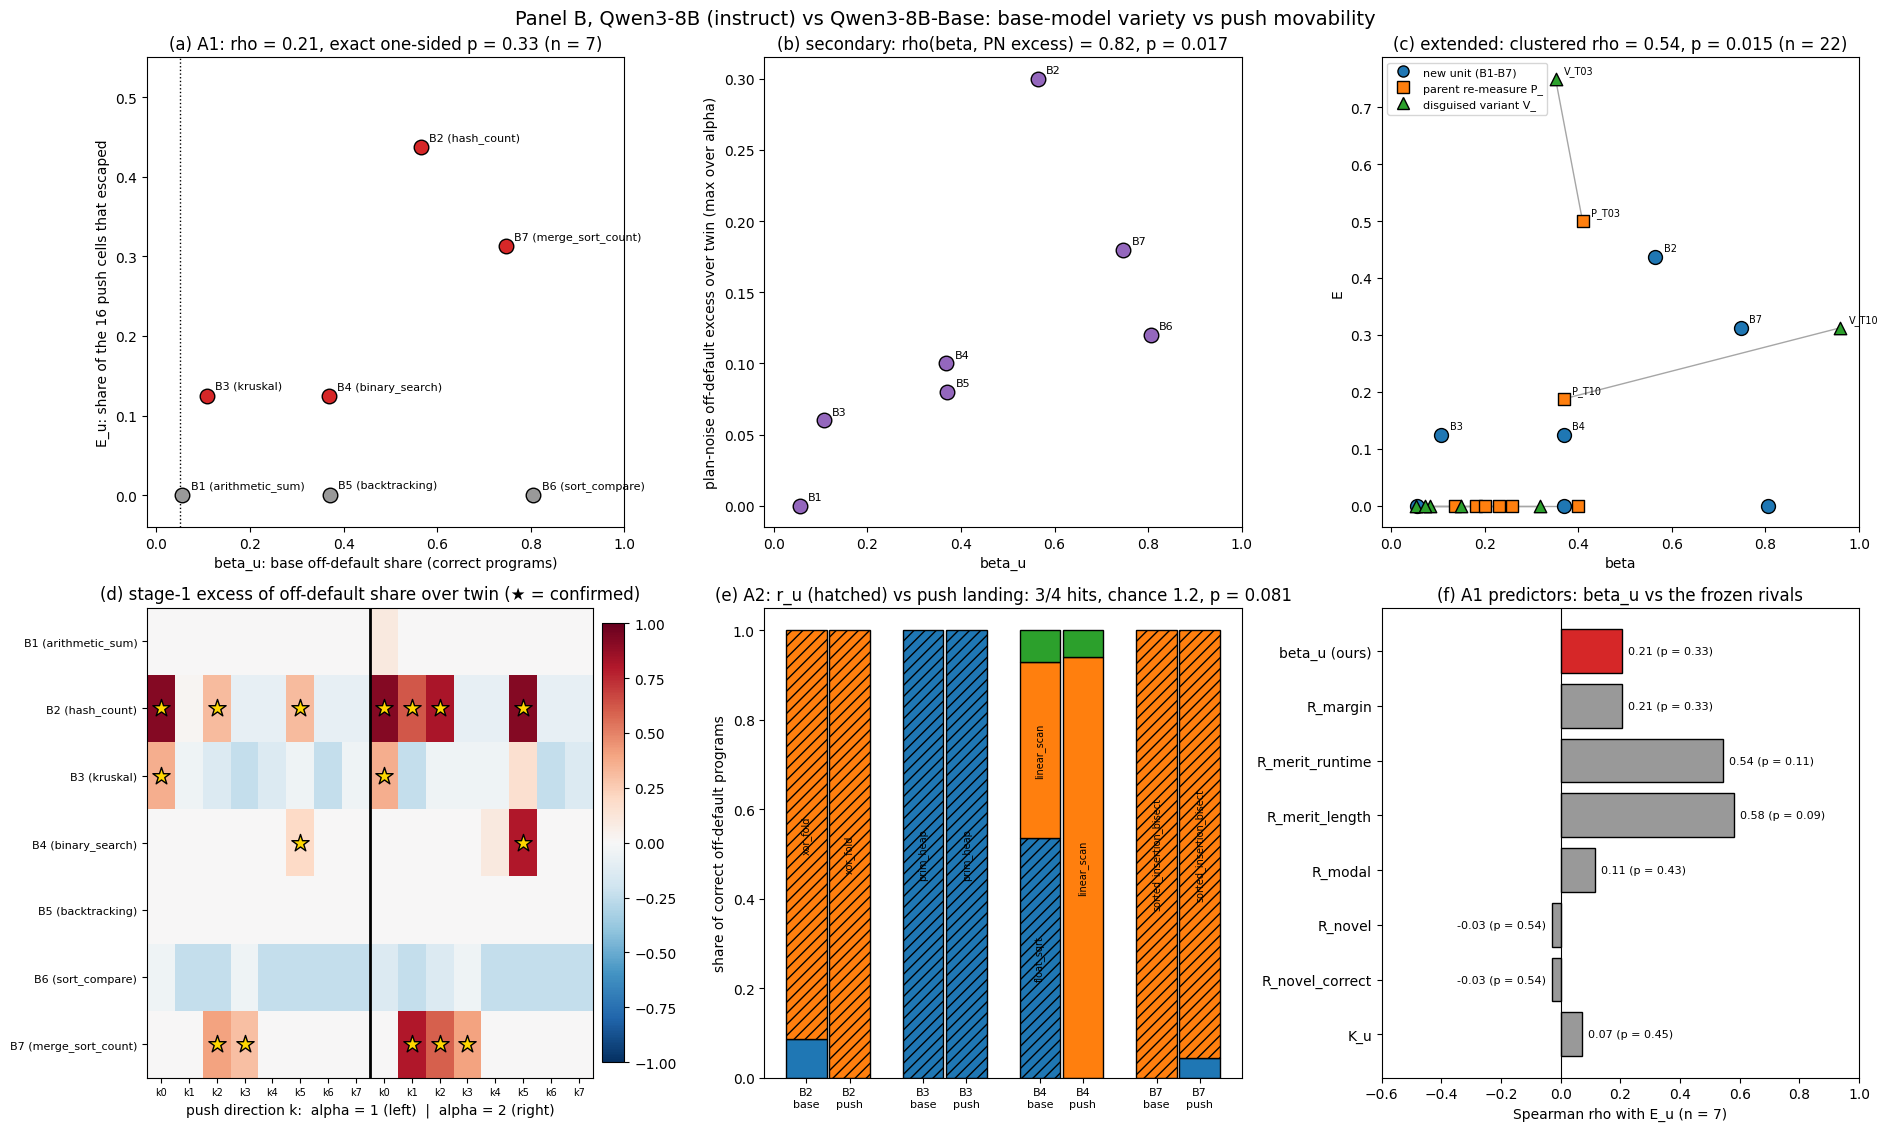

In [18]:
fig, axs = plt.subplots(2, 3, figsize=(19, 11.5))

# (a) A1 primary: beta_u vs E_u (new units)
ax = axs[0, 0]
for x in units:
    ax.scatter(x["beta_u"], x["E_u"], s=110, zorder=3, edgecolor="k", color="tab:red" if x["E_u"] > 0 else "0.6")
    ax.annotate(f"{x['unit']} ({x['default']})", (x["beta_u"], x["E_u"]), textcoords="offset points", xytext=(6, 5),
                fontsize=8)
ax.axvline(0.05, ls=":", color="k", lw=1)
ax.set_xlim(-0.02, 1.0)
ax.set_ylim(-0.04, 0.55)
ax.set_xlabel("beta_u: base off-default share (correct programs)")
ax.set_ylabel("E_u: share of the 16 push cells that escaped")
ax.set_title(f"(a) A1: rho = {r1['primary']['rho']:.2f}, exact one-sided p = {r1['primary']['p']:.2f} (n = {r1['n_units']})")

# (b) secondary target: beta_u vs plan-noise excess
ax = axs[0, 1]
for x in units:
    ax.scatter(x["beta_u"], x["PN_excess_u"], s=110, zorder=3, edgecolor="k", color="tab:purple")
    ax.annotate(x["unit"], (x["beta_u"], x["PN_excess_u"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlim(-0.02, 1.0)
ax.set_xlabel("beta_u")
ax.set_ylabel("plan-noise off-default excess over twin (max over alpha)")
ax.set_title(f"(b) secondary: rho(beta, PN excess) = {r1['secondary_PN']['rho']:.2f}, p = {r1['secondary_PN']['p']:.3f}")

# (c) extended view: new units + parents + variants, parent-variant pairs joined
ax = axs[0, 2]
vals = res_ext["values"]
for t in sorted({x["parent"] for x in U if x["parent"]}):
    if f"P_{t}" in vals and f"V_{t}" in vals:
        ax.plot([vals[f"P_{t}"]["beta"], vals[f"V_{t}"]["beta"]], [vals[f"P_{t}"]["E"], vals[f"V_{t}"]["E"]],
                color="0.65", lw=1, zorder=1)
style = {"new": ("o", "tab:blue", 100), "P_": ("s", "tab:orange", 70), "V_": ("^", "tab:green", 80)}
for x in U:
    m, c, s_ = style[x["kind"]]
    ax.scatter(x["beta"], x["E"], marker=m, color=c, s=s_, edgecolor="k", zorder=3)
    if x["E"] > 0:
        ax.annotate(x["unit"], (x["beta"], x["E"]), textcoords="offset points", xytext=(6, 4), fontsize=7)
ax.legend(handles=[plt.Line2D([], [], marker=m, ls="", color=c, markeredgecolor="k", markersize=8, label=l)
                   for (m, c, _), l in zip(style.values(), ("new unit (B1-B7)", "parent re-measure P_", "disguised variant V_"))],
          fontsize=8, loc="upper left")
ax.set_xlim(-0.02, 1.0)
ax.set_xlabel("beta")
ax.set_ylabel("E")
ax.set_title(f"(c) extended: clustered rho = {res_ext['clustered_all']['rho']:.2f}, "
             f"p = {res_ext['clustered_all']['p']:.3f} (n = {res_ext['clustered_all']['n_units']})")

# (d) escape map: stage-1 excess per (direction, alpha) cell, confirmed escapes starred
ax = axs[1, 0]
mat = np.array([[np.nan if c["excess_stage1"] is None else c["excess_stage1"] for c in x["per_direction"]]
                for x in units], dtype=float)
im = ax.imshow(mat, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
for i, x in enumerate(units):
    for j, c in enumerate(x["per_direction"]):
        if c["confirmed"]:
            ax.scatter(j, i, marker="*", s=170, color="gold", edgecolor="k", zorder=3)
ax.set_yticks(range(len(units)))
ax.set_yticklabels([f"{x['unit']} ({x['default']})" for x in units], fontsize=8)
ax.set_xticks(range(mat.shape[1]))
ax.set_xticklabels([f"k{j % N_DIRS}" for j in range(mat.shape[1])], fontsize=7)
ax.axvline(N_DIRS - 0.5, color="k", lw=2)
ax.set_xlabel("push direction k:  alpha = 1 (left)  |  alpha = 2 (right)")
ax.set_title("(d) stage-1 excess of off-default share over twin (★ = confirmed)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02)

# (e) A2: base off-default composition vs push landing composition, r_u hatched
ax = axs[1, 1]
by_unit = {x["unit"]: x for x in units}
xt, xl, pos = [], [], 0.0
for e in r2["events"]:
    x = by_unit[e["unit"]]
    base_off = {k: v for k, v in x["base_correct_composition"].items() if k != x["default"]}
    labs = sorted(set(base_off) | set(e["landing_composition"]))
    for b_i, comp in enumerate((base_off, e["landing_composition"])):
        tot, bottom = sum(comp.values()) or 1, 0.0
        for li, lab in enumerate(labs):
            h = comp.get(lab, 0) / tot
            if h > 0:
                ax.bar(pos + 0.85 * b_i, h, bottom=bottom, width=0.8, color=plt.cm.tab10(li % 10), edgecolor="k",
                       hatch="///" if lab == x["r_u"] else None)
                if h > 0.12:
                    ax.text(pos + 0.85 * b_i, bottom + h / 2, lab, ha="center", va="center", fontsize=7, rotation=90)
                bottom += h
    xt += [pos, pos + 0.85]
    xl += [f"{e['unit']}\nbase", f"{e['unit']}\npush"]
    pos += 2.3
ax.set_xticks(xt)
ax.set_xticklabels(xl, fontsize=8)
ax.set_ylabel("share of correct off-default programs")
ax.set_title(f"(e) A2: r_u (hatched) vs push landing: {r2['top1']['hits']:.0f}/{r2['top1']['n']} hits, "
             f"chance {r2['top1']['expected_by_chance']:.1f}, p = {r2['top1']['poisson_binomial_p']:.3f}")

# (f) predictors: rho with E for beta_u and the frozen rivals
ax = axs[1, 2]
names = ["beta_u (ours)"] + list(r1["rivals"])
rhos = [r1["primary"]["rho"]] + [r1["rivals"][k]["rho_rival_E"] for k in r1["rivals"]]
ps = [r1["primary"]["p"]] + [r1["rivals"][k]["p_rival"] for k in r1["rivals"]]
ax.barh(names[::-1], rhos[::-1], color=(["0.6"] * len(r1["rivals"])) + ["tab:red"], edgecolor="k")
for i, (r, p) in enumerate(zip(rhos[::-1], ps[::-1])):
    ax.text(r + (0.02 if r >= 0 else -0.02), i, f"{r:.2f} (p = {p:.2f})", va="center",
            ha="left" if r >= 0 else "right", fontsize=8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlim(-0.6, 1.0)
ax.set_xlabel("Spearman rho with E_u (n = 7)")
ax.set_title("(f) A1 predictors: beta_u vs the frozen rivals")

fig.suptitle("Panel B, Qwen3-8B (instruct) vs Qwen3-8B-Base: base-model variety vs push movability", fontsize=14)
fig.tight_layout()
plt.show()

## Reading the results

* **A1 is not supported within panel B.** β_u barely ranks E_u (ρ = 0.21, exact p = 0.33, n = 7).
  * The units that moved (B2, B3, B4, B7) and the ones that did not (B1, B5, B6) overlap in β.
  * Two clearly base-diverse units stayed immovable at α ≤ 2: B5 (β = 0.37) and B6 (β = 0.81, the clearest disconfirming case). B1 (β = 0.06) did not move either.
  * Every new unit had β ≥ 0.05, so the "collapsed → immovable" half of the claim is untested here.
* **Graded movability agrees better.** β_u ranks the plan-noise excess well (ρ = 0.82, p = 0.017). The descriptive views are positive too: adding the re-measured parents gives ρ = 0.43 (n = 15), and the cluster-preserving view with the variants gives ρ = 0.54, p = 0.015 (n = 22). None of these is the pre-registered primary test.
* **A2 is suggestive.** When pushes did move the model, they landed on the base model's committed runner-up r_u in 3 of 4 events (chance 1.2, p = 0.08). The base composition out-scored the association forecast by 0.68 nats per event and AST proximity by 0.13 nats. With fewer than 5 events this stays descriptive.
* **Rival predictors.** R_merit has the largest ρ with E (0.54–0.58): it asks whether a non-default reference is faster or shorter. Every paired CI of ρ(β) − ρ(rival) spans zero at n = 7.
* **Within-parent test.** Only T03 and T10 move. T10's variant also changes the default (union_find → bfs), so a narrative disguise can shift the default itself.

**For the underlying question** (*does the instruct model give the "average" answer, and can a nudge move it into another region?*), the descriptive pattern in panel B is this:
* isotropic random pushes do move some tasks off their default algorithm without any prompt ban;
* when they do, the model tends to land on the algorithm the **base** model already ranked second;
* *whether* a task moves at all is not predicted by how varied the base model is on it.

These panel-B numbers go into the pooled panel A + B test of the next round (`pooled_inputs.json` in the artifact).